In [2]:
import networkx as nx
import matplotlib.pyplot as plt

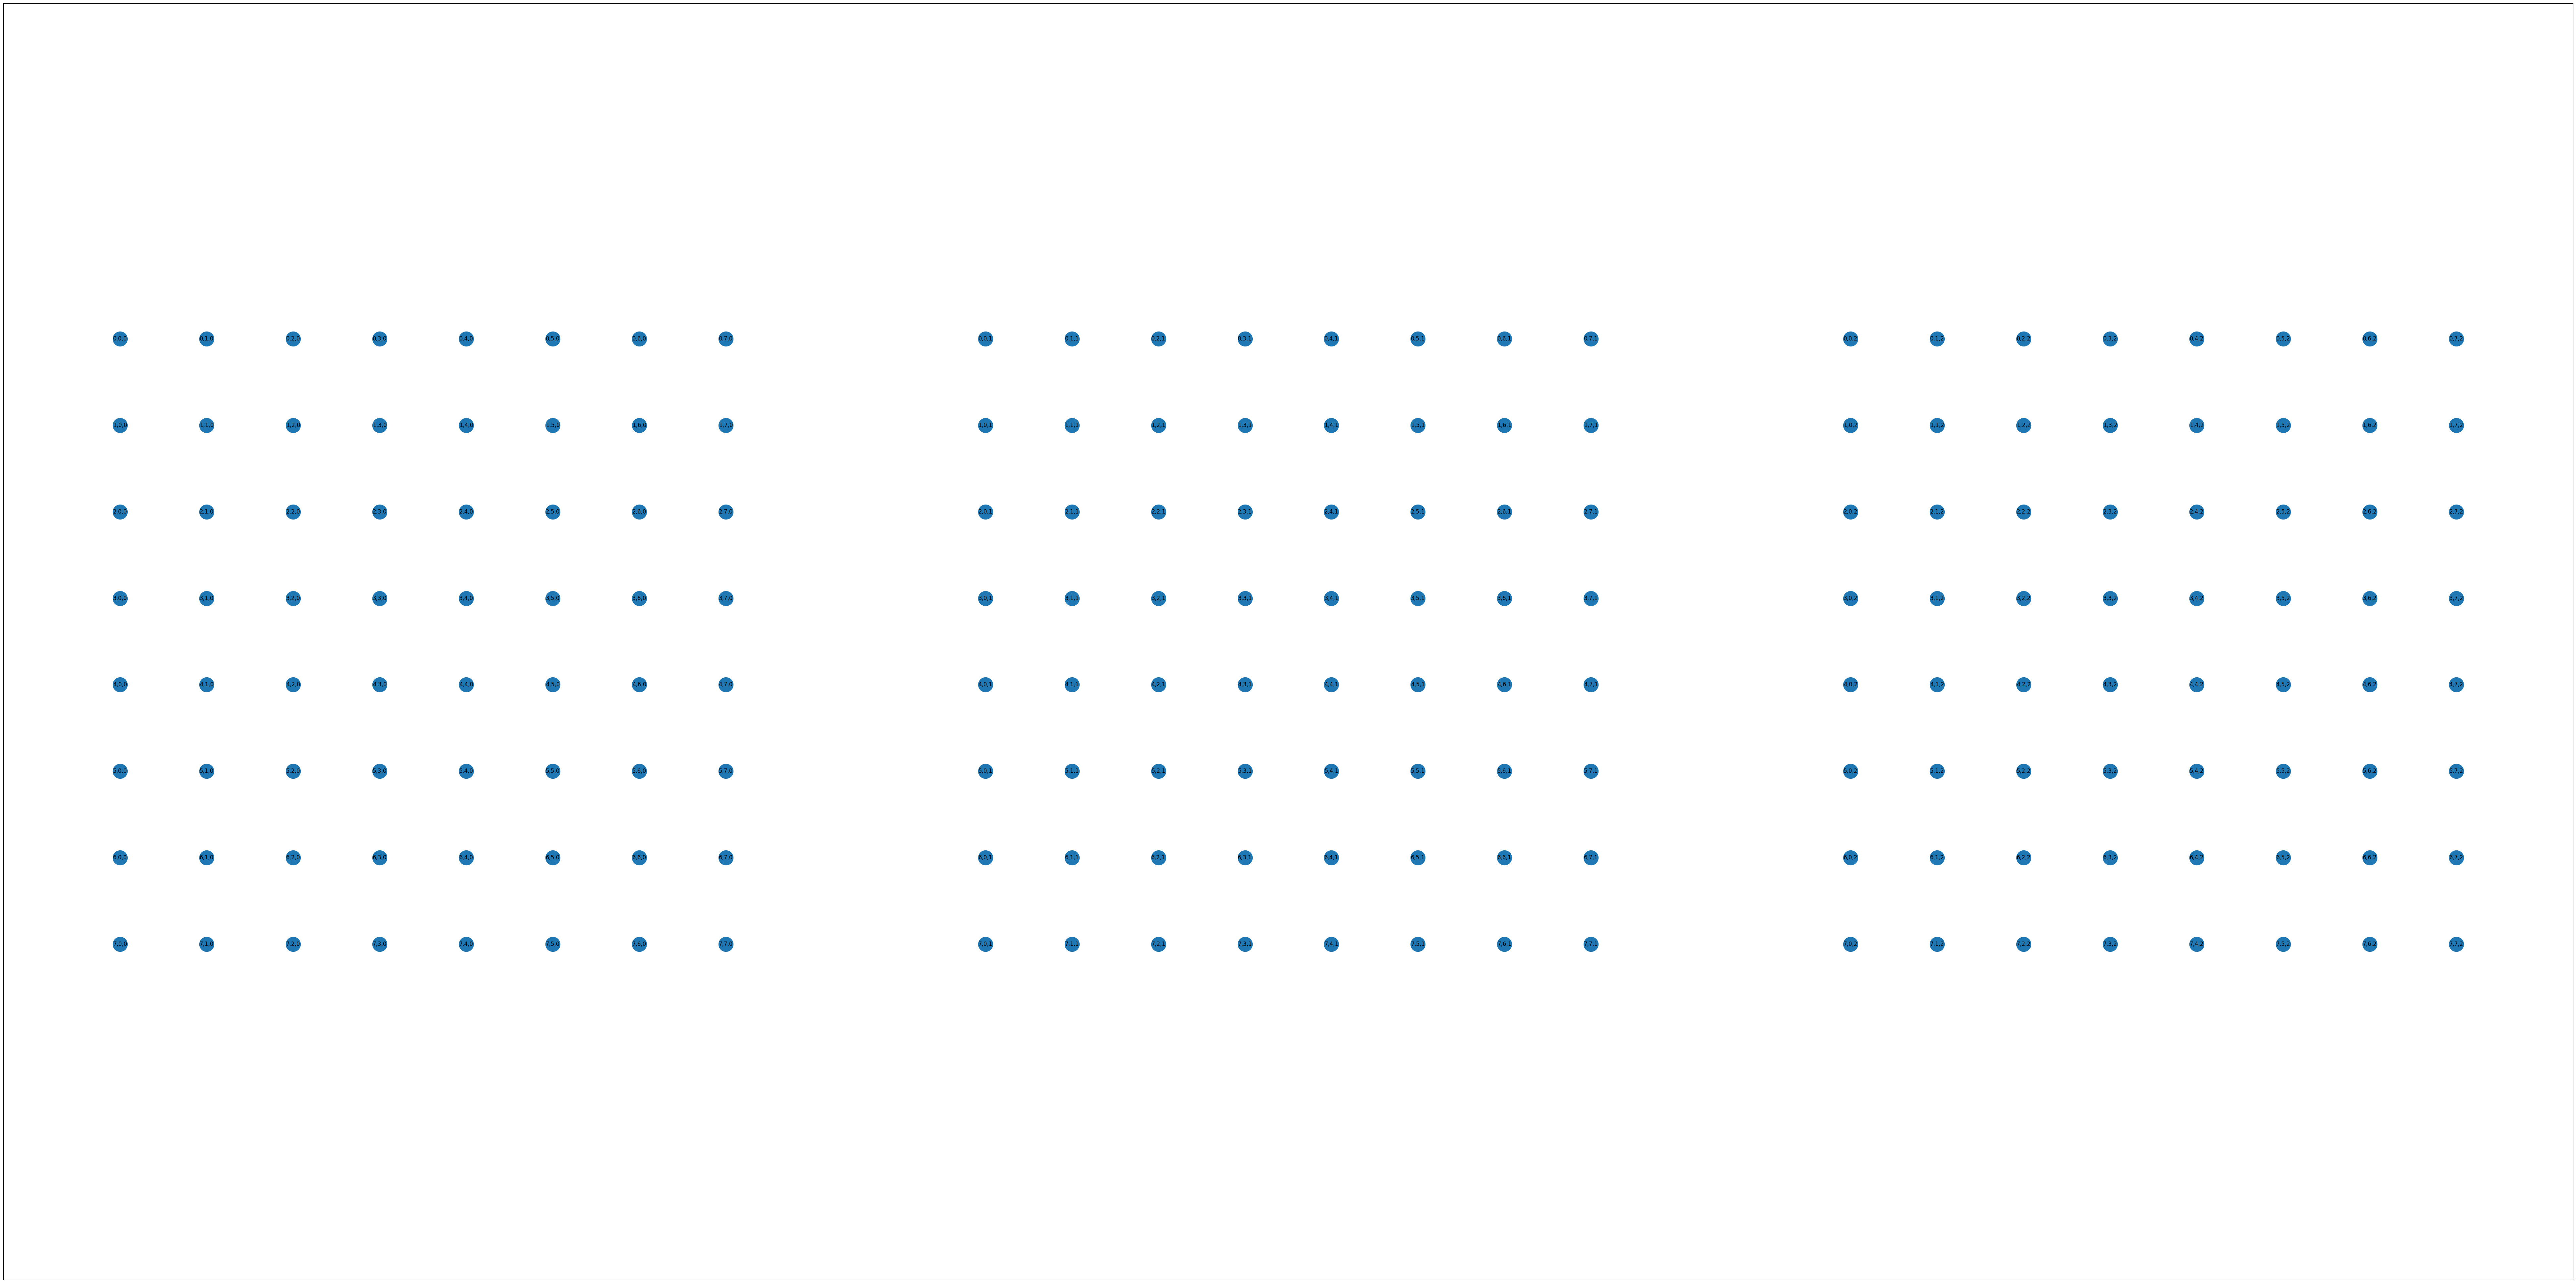

In [3]:
graphs = 3
N = 8
G = nx.Graph()

for g in range(graphs):
  for i in range(N):
    for j in range(N):
      G.add_node(f'{i},{j},{g}')

get_corr = lambda x: (int(x.split(',')[0]), int(x.split(',')[1]))
pos = {k: (get_corr(k)[1] + int(k.split(',')[2]) * 10, N - 1 - get_corr(k)[0]) for k in G.nodes()}

plt.figure(figsize=(100, 50))
nx.draw_networkx(G, pos=pos, with_labels=True, node_size=1000)
plt.axis('equal')
plt.show()

In [4]:
from pprint import pprint

matr = [
 [(i, j) for j in range(N)]
 for i in range(N)
]

pprint(matr)


[[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7)],
 [(1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7)],
 [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7)],
 [(3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (3, 7)],
 [(4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7)],
 [(5, 0), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 6), (5, 7)],
 [(6, 0), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6), (6, 7)],
 [(7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7)]]


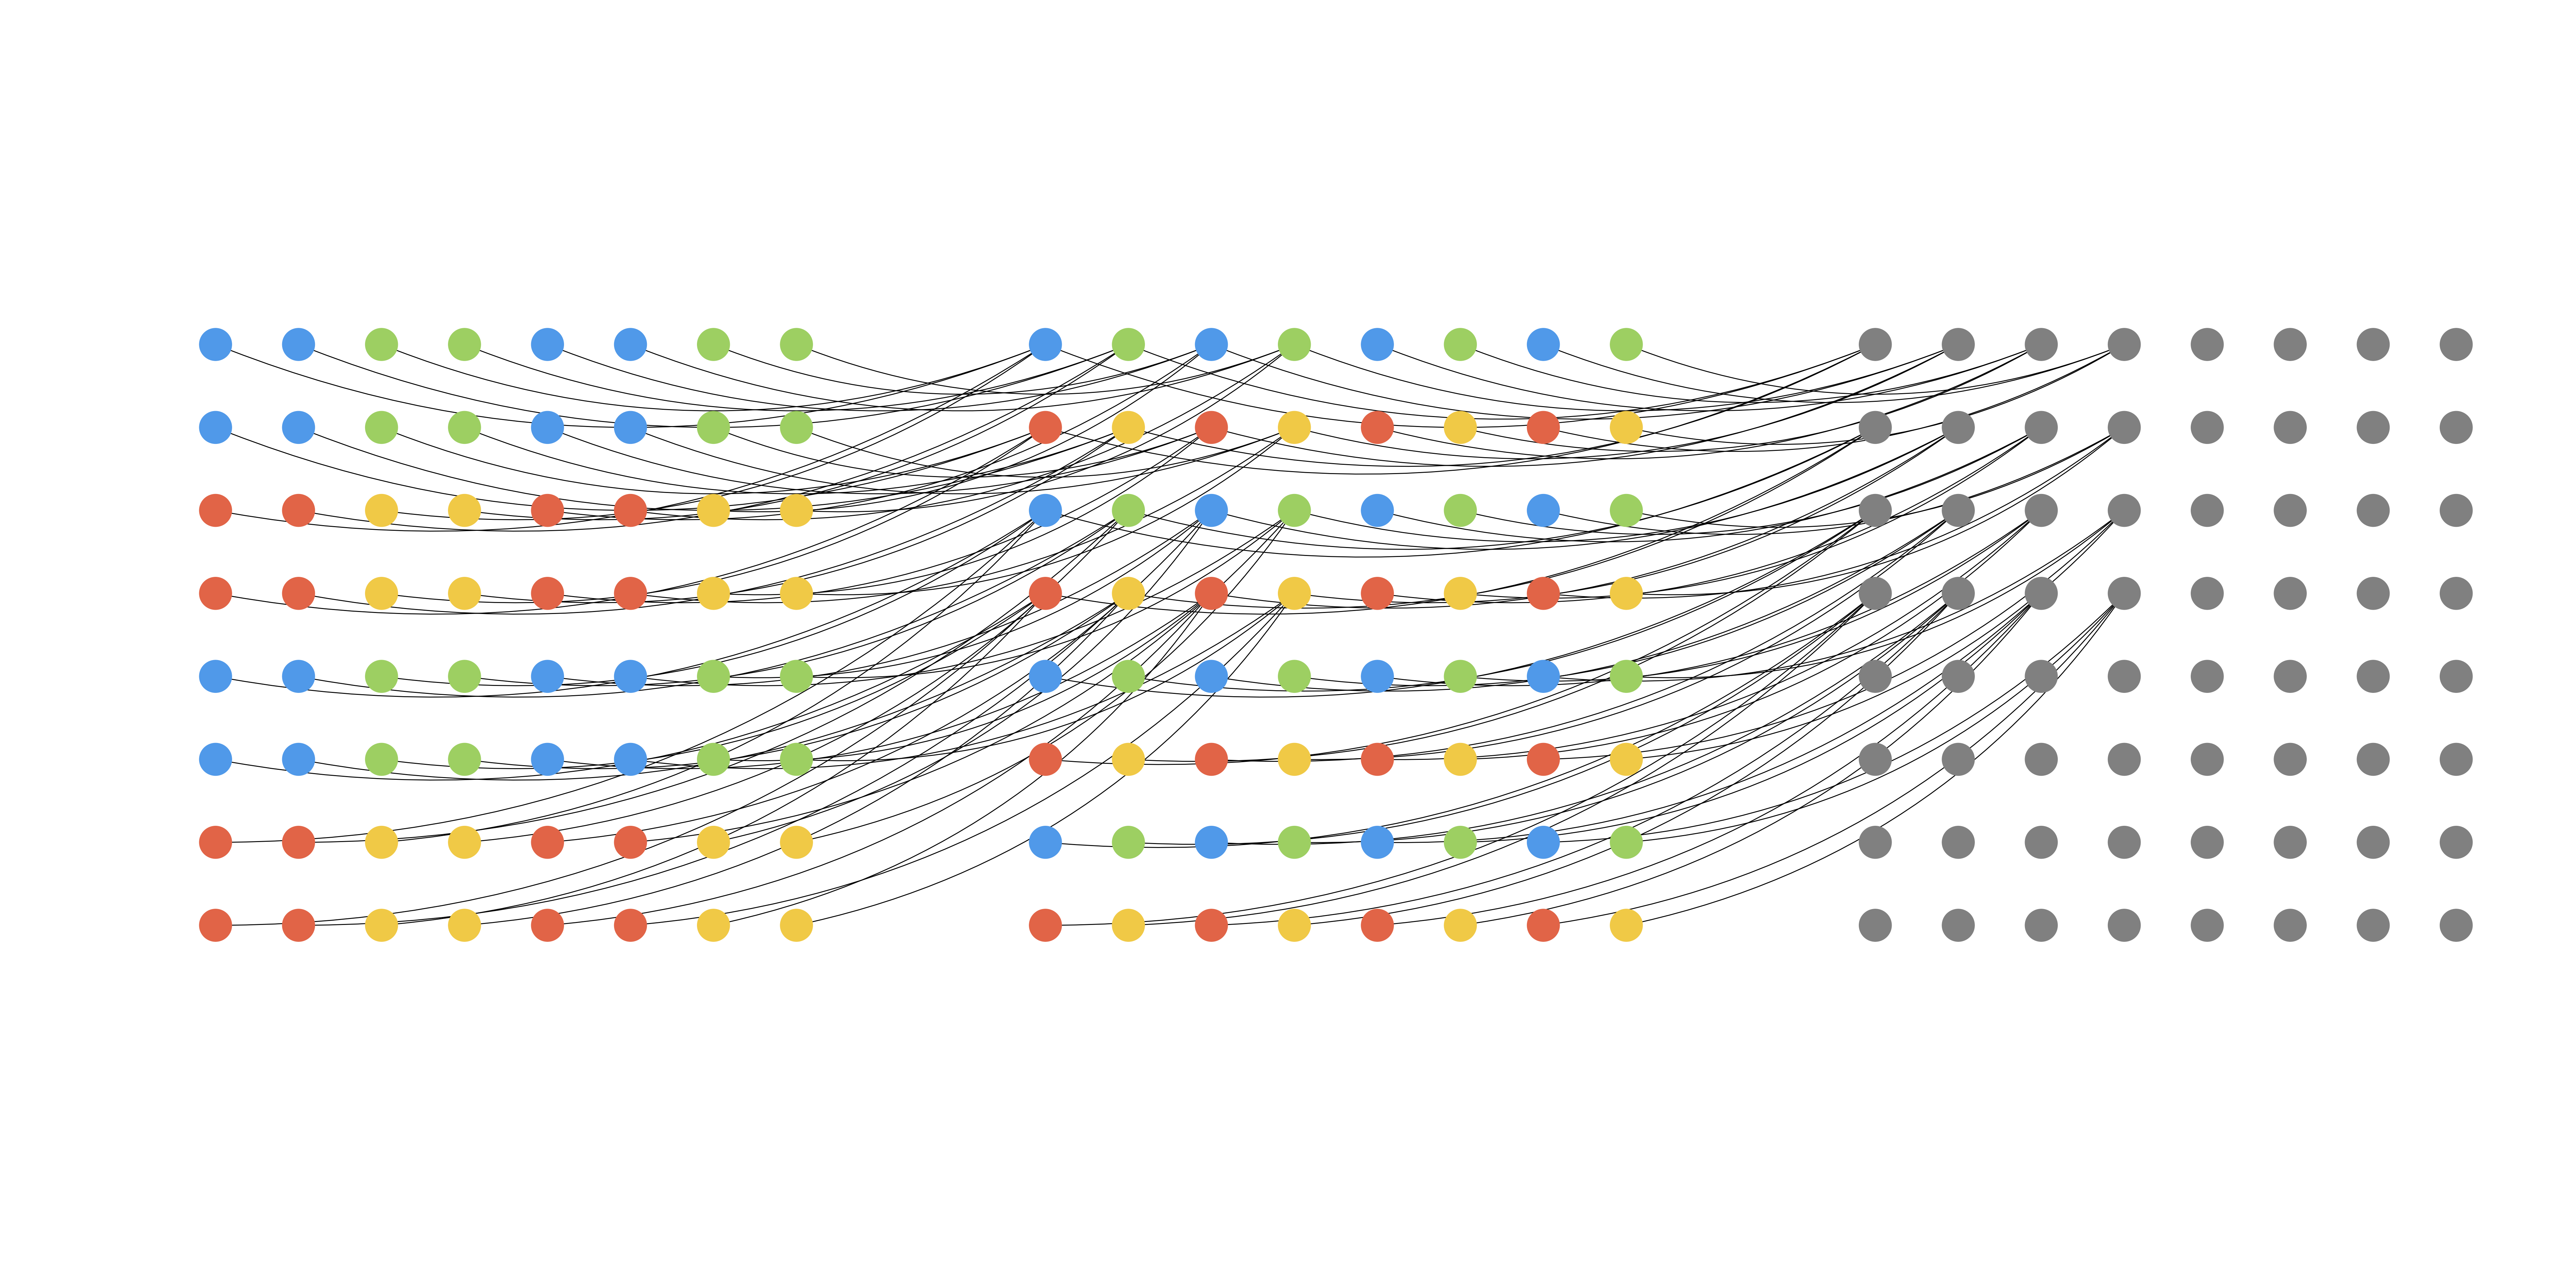

In [ ]:

edges = list()
node_colors = dict()

def fft(mat, level):
  sz = len(mat)
  n = int(len(mat) / 2)
  if n == 1: return
  blue = [
    [mat[i][j] for j in range(sz) if j & 1 == 0]
    for i in range(sz)
    if i & 1 == 0
  ]
  green = [
    [mat[i][j] for j in range(sz) if j & 1 == 1]
    for i in range(sz)
    if i & 1 == 0
  ]
  red = [
    [mat[i][j] for j in range(sz) if j & 1 == 0]
    for i in range(sz)
    if i & 1 == 1
  ]
  black = [
    [mat[i][j] for j in range(sz) if j & 1 == 1]
    for i in range(sz)
    if i & 1 == 1
  ]
  fft(blue,   level - 1)
  fft(green,  level - 1)
  fft(red,    level - 1)
  fft(black, level - 1)

  mats = [blue, green, red, black]
  cols = ['blue', 'green', 'red', 'yellow']
  for mt in range(len(mats)):
    for line in mats[mt]:
      for x in line:
        ci, cj = x
        node_colors[f'{ci},{cj},{level - 1}'] = cols[mt]

  for i in range(n):
    for j in range(n):
      edges.append(((mat[i][j], level), (blue[i][j], level - 1), 'blue'))
      edges.append(((mat[i][j], level), (green[i][j], level - 1), 'green'))
      edges.append(((mat[i][j], level), (red[i][j], level - 1), 'red'))
      edges.append(((mat[i][j], level), (black[i][j], level - 1), 'yellow'))
      # edges.append(((mat[i][j], level), (blue[i][j], level - 1), '#5099e9'))
      # edges.append(((mat[i][j], level), (green[i][j], level - 1), '#9dcf62'))
      # edges.append(((mat[i][j], level), (red[i][j], level - 1), '#e16447'))
      # edges.append(((mat[i][j], level), (black[i][j], level - 1), '#f0c946'))

G = nx.Graph()
for g in range(graphs):
  for i in range(N):
    for j in range(N):
      G.add_node(f'{i},{j},{g}')

fft(matr, 2)

for (a, b, c) in edges:
  fr = f'{a[0][0]},{a[0][1]},{a[1]}'
  to = f'{b[0][0]},{b[0][1]},{b[1]}'
  G.add_edge(fr, to, color=c)

color_map = {
  'blue': '#5099e9',
  'green': '#9dcf62',
  'red': '#e16447',
  'yellow': '#f0c946',
  'black': '#808080',
}


# edge_colors = [G[u][v]['color'] for u, v in G.edges()]
node_color = [color_map[node_colors.get(node, 'black')] for node in G.nodes()]

plt.figure(figsize=(100, 50))
plt.axis('off')
nx.draw_networkx(G,
  connectionstyle='arc3,rad=0.2',
  arrows=True,
  pos=pos,
  with_labels=False,
  # edge_color=edge_colors,
  node_color=node_color,
  node_size=10000 / 2,
  width=2
)
plt.axis('equal')
plt.show()

{'0,0,1': ['0,0,0', '0,2,0', '2,0,0', '2,2,0'], '0,4,1': ['0,4,0', '0,6,0', '2,4,0', '2,6,0'], '4,0,1': ['4,0,0', '4,2,0', '6,0,0', '6,2,0'], '4,4,1': ['4,4,0', '4,6,0', '6,4,0', '6,6,0'], '0,2,1': ['0,0,0', '0,2,0', '2,0,0', '2,2,0'], '0,6,1': ['0,4,0', '0,6,0', '2,4,0', '2,6,0'], '4,2,1': ['4,0,0', '4,2,0', '6,0,0', '6,2,0'], '4,6,1': ['4,4,0', '4,6,0', '6,4,0', '6,6,0'], '2,0,1': ['0,0,0', '0,2,0', '2,0,0', '2,2,0'], '2,4,1': ['0,4,0', '0,6,0', '2,4,0', '2,6,0'], '6,0,1': ['4,0,0', '4,2,0', '6,0,0', '6,2,0'], '6,4,1': ['4,4,0', '4,6,0', '6,4,0', '6,6,0'], '2,2,1': ['0,0,0', '0,2,0', '2,0,0', '2,2,0'], '2,6,1': ['0,4,0', '0,6,0', '2,4,0', '2,6,0'], '6,2,1': ['4,0,0', '4,2,0', '6,0,0', '6,2,0'], '6,6,1': ['4,4,0', '4,6,0', '6,4,0', '6,6,0'], '0,1,1': ['0,1,0', '0,3,0', '2,1,0', '2,3,0'], '0,5,1': ['0,5,0', '0,7,0', '2,5,0', '2,7,0'], '4,1,1': ['4,1,0', '4,3,0', '6,1,0', '6,3,0'], '4,5,1': ['4,5,0', '4,7,0', '6,5,0', '6,7,0'], '0,3,1': ['0,1,0', '0,3,0', '2,1,0', '2,3,0'], '0,7,1': ['0

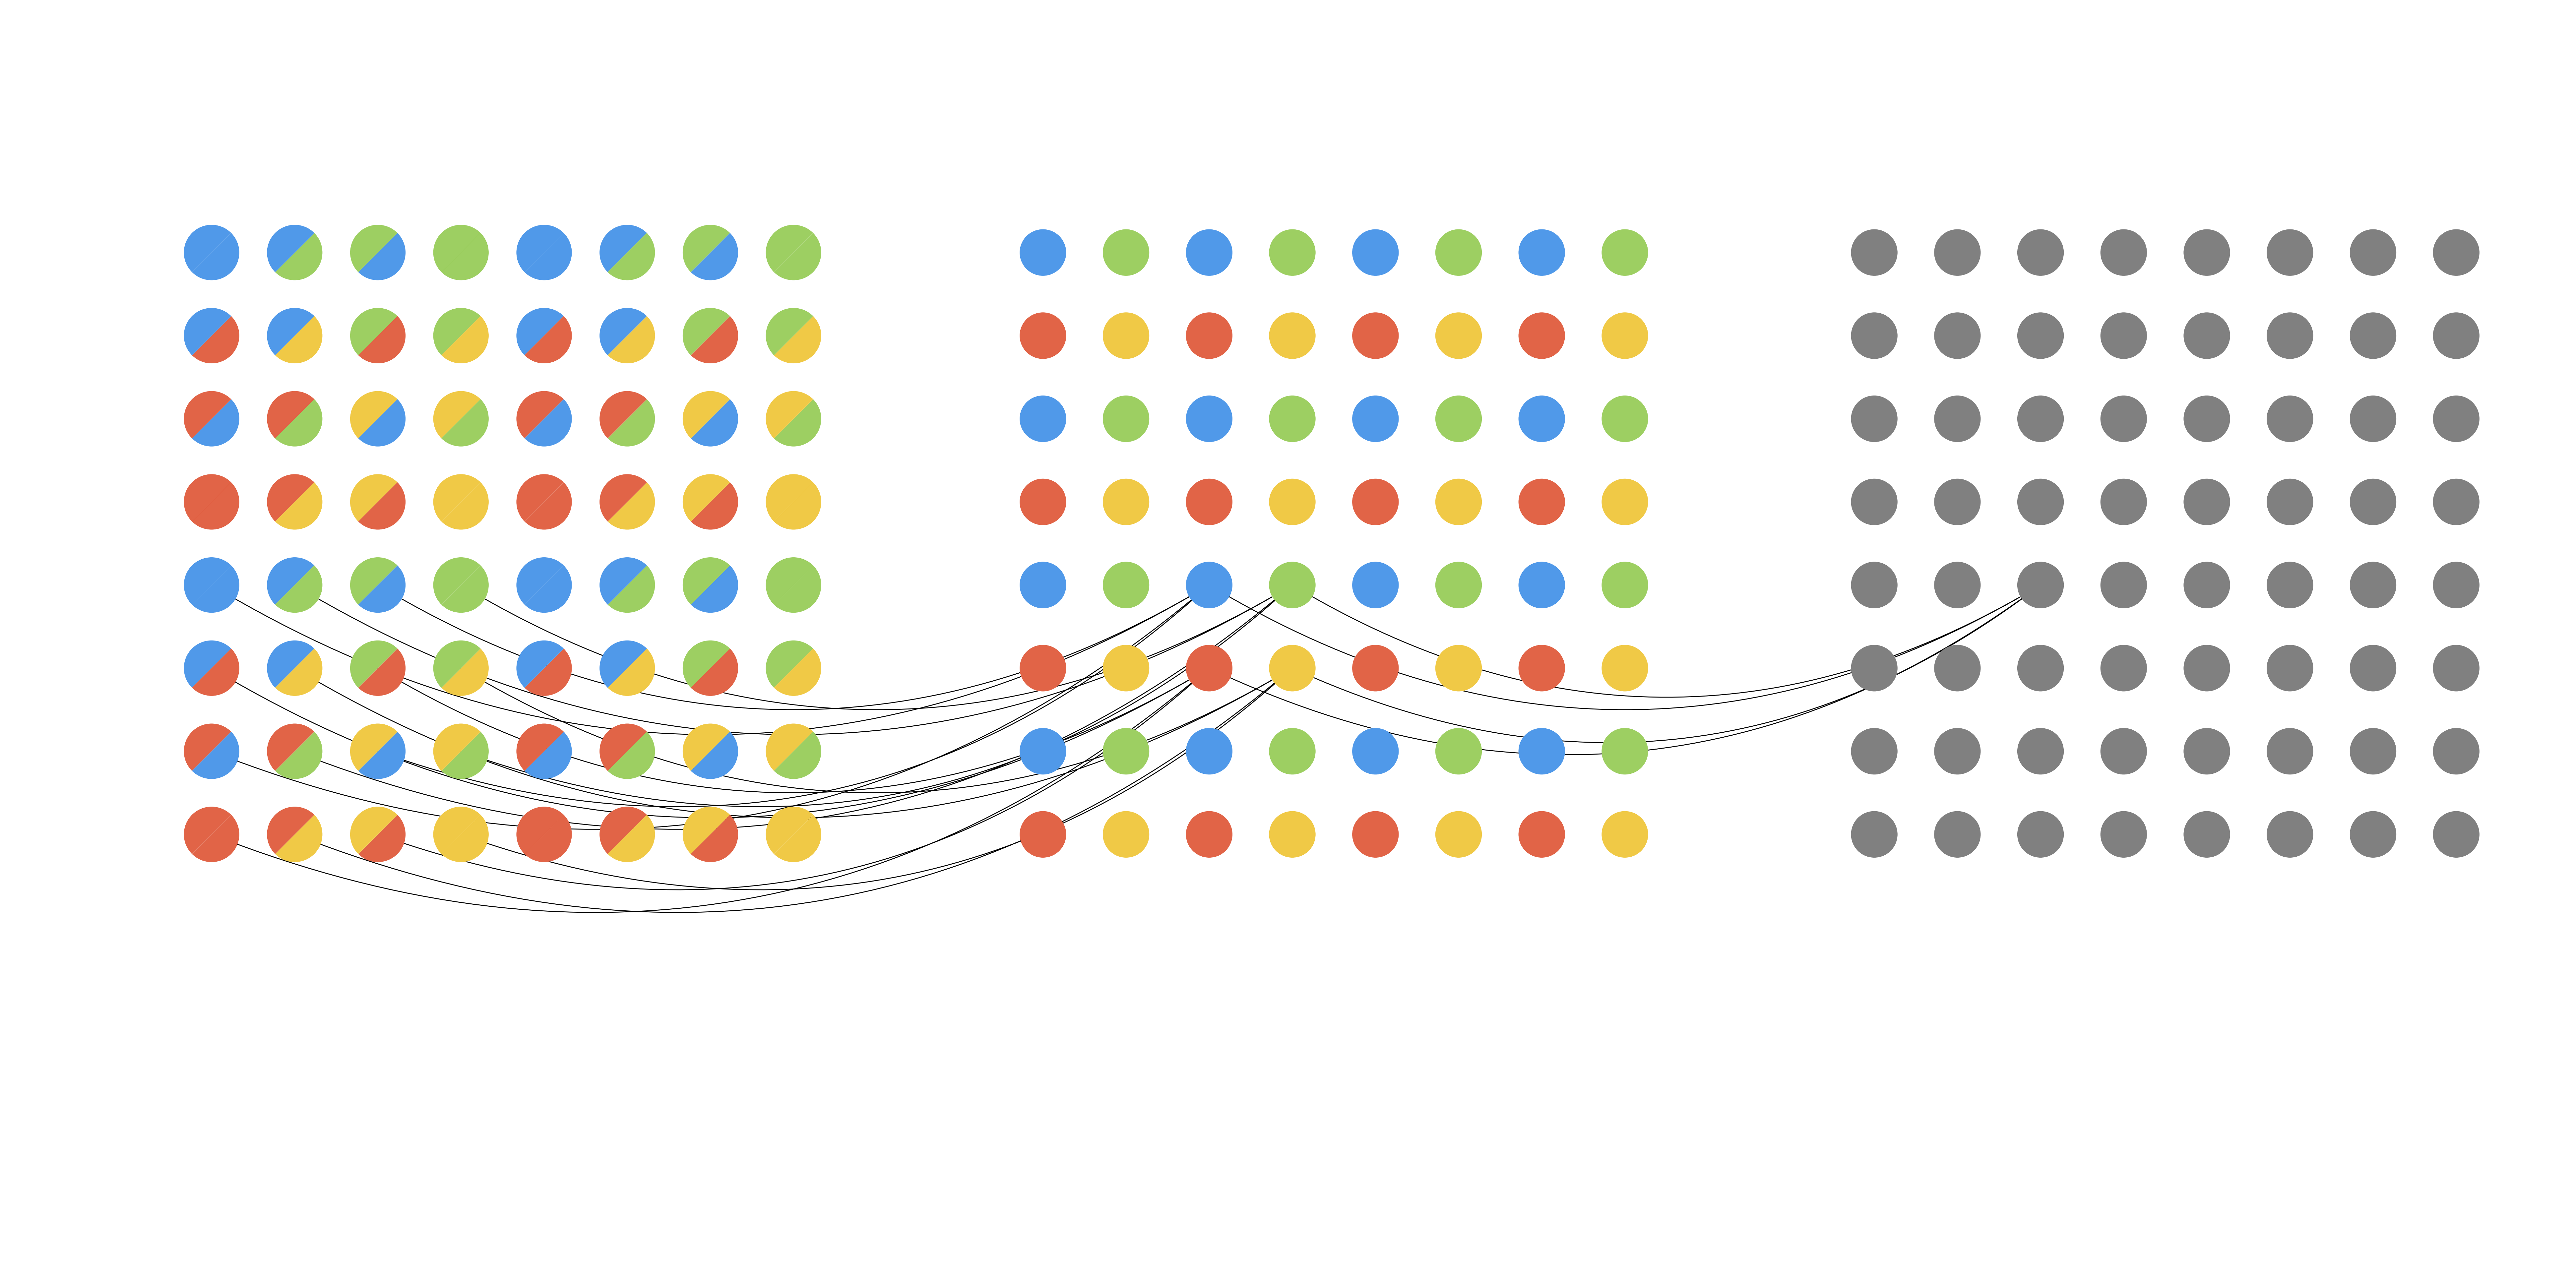

In [105]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

edges = []
node_colors = {}

def fft(mat, level, prev_rec_color=None):
    sz = len(mat)
    n = sz // 2
    if n == 1:
        return

    blue = [
        [mat[i][j] for j in range(sz) if j & 1 == 0]
        for i in range(sz)
        if i & 1 == 0
    ]
    green = [
        [mat[i][j] for j in range(sz) if j & 1 == 1]
        for i in range(sz)
        if i & 1 == 0
    ]
    red = [
        [mat[i][j] for j in range(sz) if j & 1 == 0]
        for i in range(sz)
        if i & 1 == 1
    ]
    black = [
        [mat[i][j] for j in range(sz) if j & 1 == 1]
        for i in range(sz)
        if i & 1 == 1
    ]
    fft(blue,  level - 1, 'blue')
    fft(green, level - 1, 'green')
    fft(red,   level - 1, 'red')
    fft(black, level - 1, 'yellow')

    mats = [blue, green, red, black]
    cols = ['blue', 'green', 'red', 'yellow']

    # Assign colors to sub-block nodes
    for mt in range(len(mats)):
        for line in mats[mt]:
            for x in line:
                ci, cj = x
                color_name = cols[mt]
                if prev_rec_color: color_name += f'_{prev_rec_color}'
                node_colors[f'{ci},{cj},{level - 1}'] = color_name


    # Add edges from the "parent" block to each "child" block
    for di in range(2):
      for dj in range(2):
        for i in range(n):
            for j in range(n):
                edges.append(((mat[2 * i + di][2 * j+ dj], level), (blue[i][j],  level - 1)))
                edges.append(((mat[2 * i + di][2 * j+ dj], level), (green[i][j], level - 1)))
                edges.append(((mat[2 * i + di][2 * j+ dj], level), (red[i][j],   level - 1)))
                edges.append(((mat[2 * i + di][2 * j+ dj], level), (black[i][j], level - 1)))


# -------------------------------
# 1. Build your graph G normally
# -------------------------------
G = nx.Graph()

N = 8        # Example dimension
graphs = 3   # Example "levels" or something from your code
matr = [ [ (i, j) for j in range(N)] for i in range(N) ]

for g in range(graphs):
    for i in range(N):
        for j in range(N):
            G.add_node(f'{i},{j},{g}')

fft(matr, 2)  # populate edges & node_colors

# Add edges to G

eds = []
for (a, b) in edges:
    # a = ((row,col), level)
    # b = ((row,col), level-1)
    fr = f'{a[0][0]},{a[0][1]},{a[1]}'
    to = f'{b[0][0]},{b[0][1]},{b[1]}'
    eds.append((fr, to))

joint_matrix = {

}

for (a, b) in eds:
  joint_matrix[a] = joint_matrix.get(a, [])
  joint_matrix[a].append(b)


print(joint_matrix)

used = set()
resulting_edges = []

def dfs(start):
  used.add(start)
  for nxt in joint_matrix.get(start, []):
    if nxt not in used:
      resulting_edges.append((start, nxt))
      dfs(nxt)

dfs('4,2,2')

for (fr, to) in resulting_edges:
  G.add_edge(fr, to)


# -------------------------------------------------------
# 2. Define a color_map for single-colored nodes
#    and optionally mark some node(s) as "half-blue-green"
# -------------------------------------------------------
color_map = {
    'blue':   '#5099e9',
    'green':  '#9dcf62',
    'red':    '#e16447',
    'yellow': '#f0c946',
    'black':  '#808080',
    # We'll handle 'blue_green' manually => no direct color
}


# ----------------------------------------------------
# 3. Prepare to draw manually with Matplotlib
#    instead of using nx.draw_networkx all at once
# ----------------------------------------------------
pos = {k: (get_corr(k)[1] + int(k.split(',')[2]) * 10, N - 1 - get_corr(k)[0]) for k in G.nodes()}


fig, ax = plt.subplots(figsize=(100, 50))
plt.axis('off')

nx.draw_networkx_edges(
    G, pos,
    ax=ax,
    # edge_color=edge_colors,
    connectionstyle='arc3,rad=0.3',
    width=2,
    arrows=True
)

# 3b. Split nodes into "normal" single-colored vs. "half-blue-green"
normal_nodes   = []
special_nodes  = []
for n in G.nodes():
    node_col_label = node_colors.get(n, 'black')
    if len(node_col_label.split('_')) == 2:
        special_nodes.append(n)
    else:
        normal_nodes.append(n)

# 3c. Draw NORMAL single-color nodes
node_size = 10000
nx.draw_networkx_nodes(
    G, pos,
    nodelist=normal_nodes,
    node_color=[ color_map[node_colors.get(n, 'black')] for n in normal_nodes ],
    node_size=node_size,
    ax=ax
)

# 3d. Manually draw the SPECIAL half-blue-half-green nodes
for n in special_nodes:
    x, y = pos[n]
    radius = (node_size) ** 0.5 / 300
    color = node_colors.get(n)

    # Top half = blue wedge
    wedge1 = mpatches.Wedge(
        center=(x, y),
        r=radius,
        theta1=-45 - 90,
        theta2=-45 -90 + 180,   # top half
        facecolor=color_map[color.split('_')[1]]
    )
    # Bottom half = green wedge
    wedge2 = mpatches.Wedge(
        center=(x, y),
        r=radius,
        theta1=45,
        theta2=45 + 180,   # bottom half
        facecolor=color_map[color.split('_')[0]]
    )
    ax.add_patch(wedge1)
    ax.add_patch(wedge2)

# 3e. (Optional) Draw labels
# nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)

plt.axis('equal')
plt.show()

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

class RoundedSquare(mpatches.Rectangle):
    def __init__(self, xy, width, height, radius=0.2, **kwargs):
        super().__init__(xy, width, height, **kwargs)
        self.radius = radius
        self._patch_transform = None

    def __lt__(self, other):
        return (self.get_x(), self.get_y()) < (other.get_x(), other.get_y())

    def __gt__(self, other):
        return (self.get_x(), self.get_y()) > (other.get_x(), other.get_y())

    def __eq__(self, other):
        return (self.get_x(), self.get_y()) == (other.get_x(), other.get_y())

    def get_path(self):
        import matplotlib.path as mpath

        rx, ry = self.radius, self.radius
        w, h = self.get_width(), self.get_height()

        # Define rounded rectangle path
        path_data = [
            (mpath.Path.MOVETO, (rx, 0)),
            (mpath.Path.LINETO, (w-rx, 0)),
            (mpath.Path.CURVE4, (w, 0), (w, ry)),
            (mpath.Path.LINETO, (w, h-ry)),
            (mpath.Path.CURVE4, (w, h), (w-rx, h)),
            (mpath.Path.LINETO, (rx, h)),
            (mpath.Path.CURVE4, (0, h), (0, h-ry)),
            (mpath.Path.LINETO, (0, ry)),
            (mpath.Path.CURVE4, (0, 0), (rx, 0)),
            (mpath.Path.CLOSEPOLY, (0, 0))
        ]

        codes, verts = zip(*path_data)
        return mpath.Path(verts, codes)

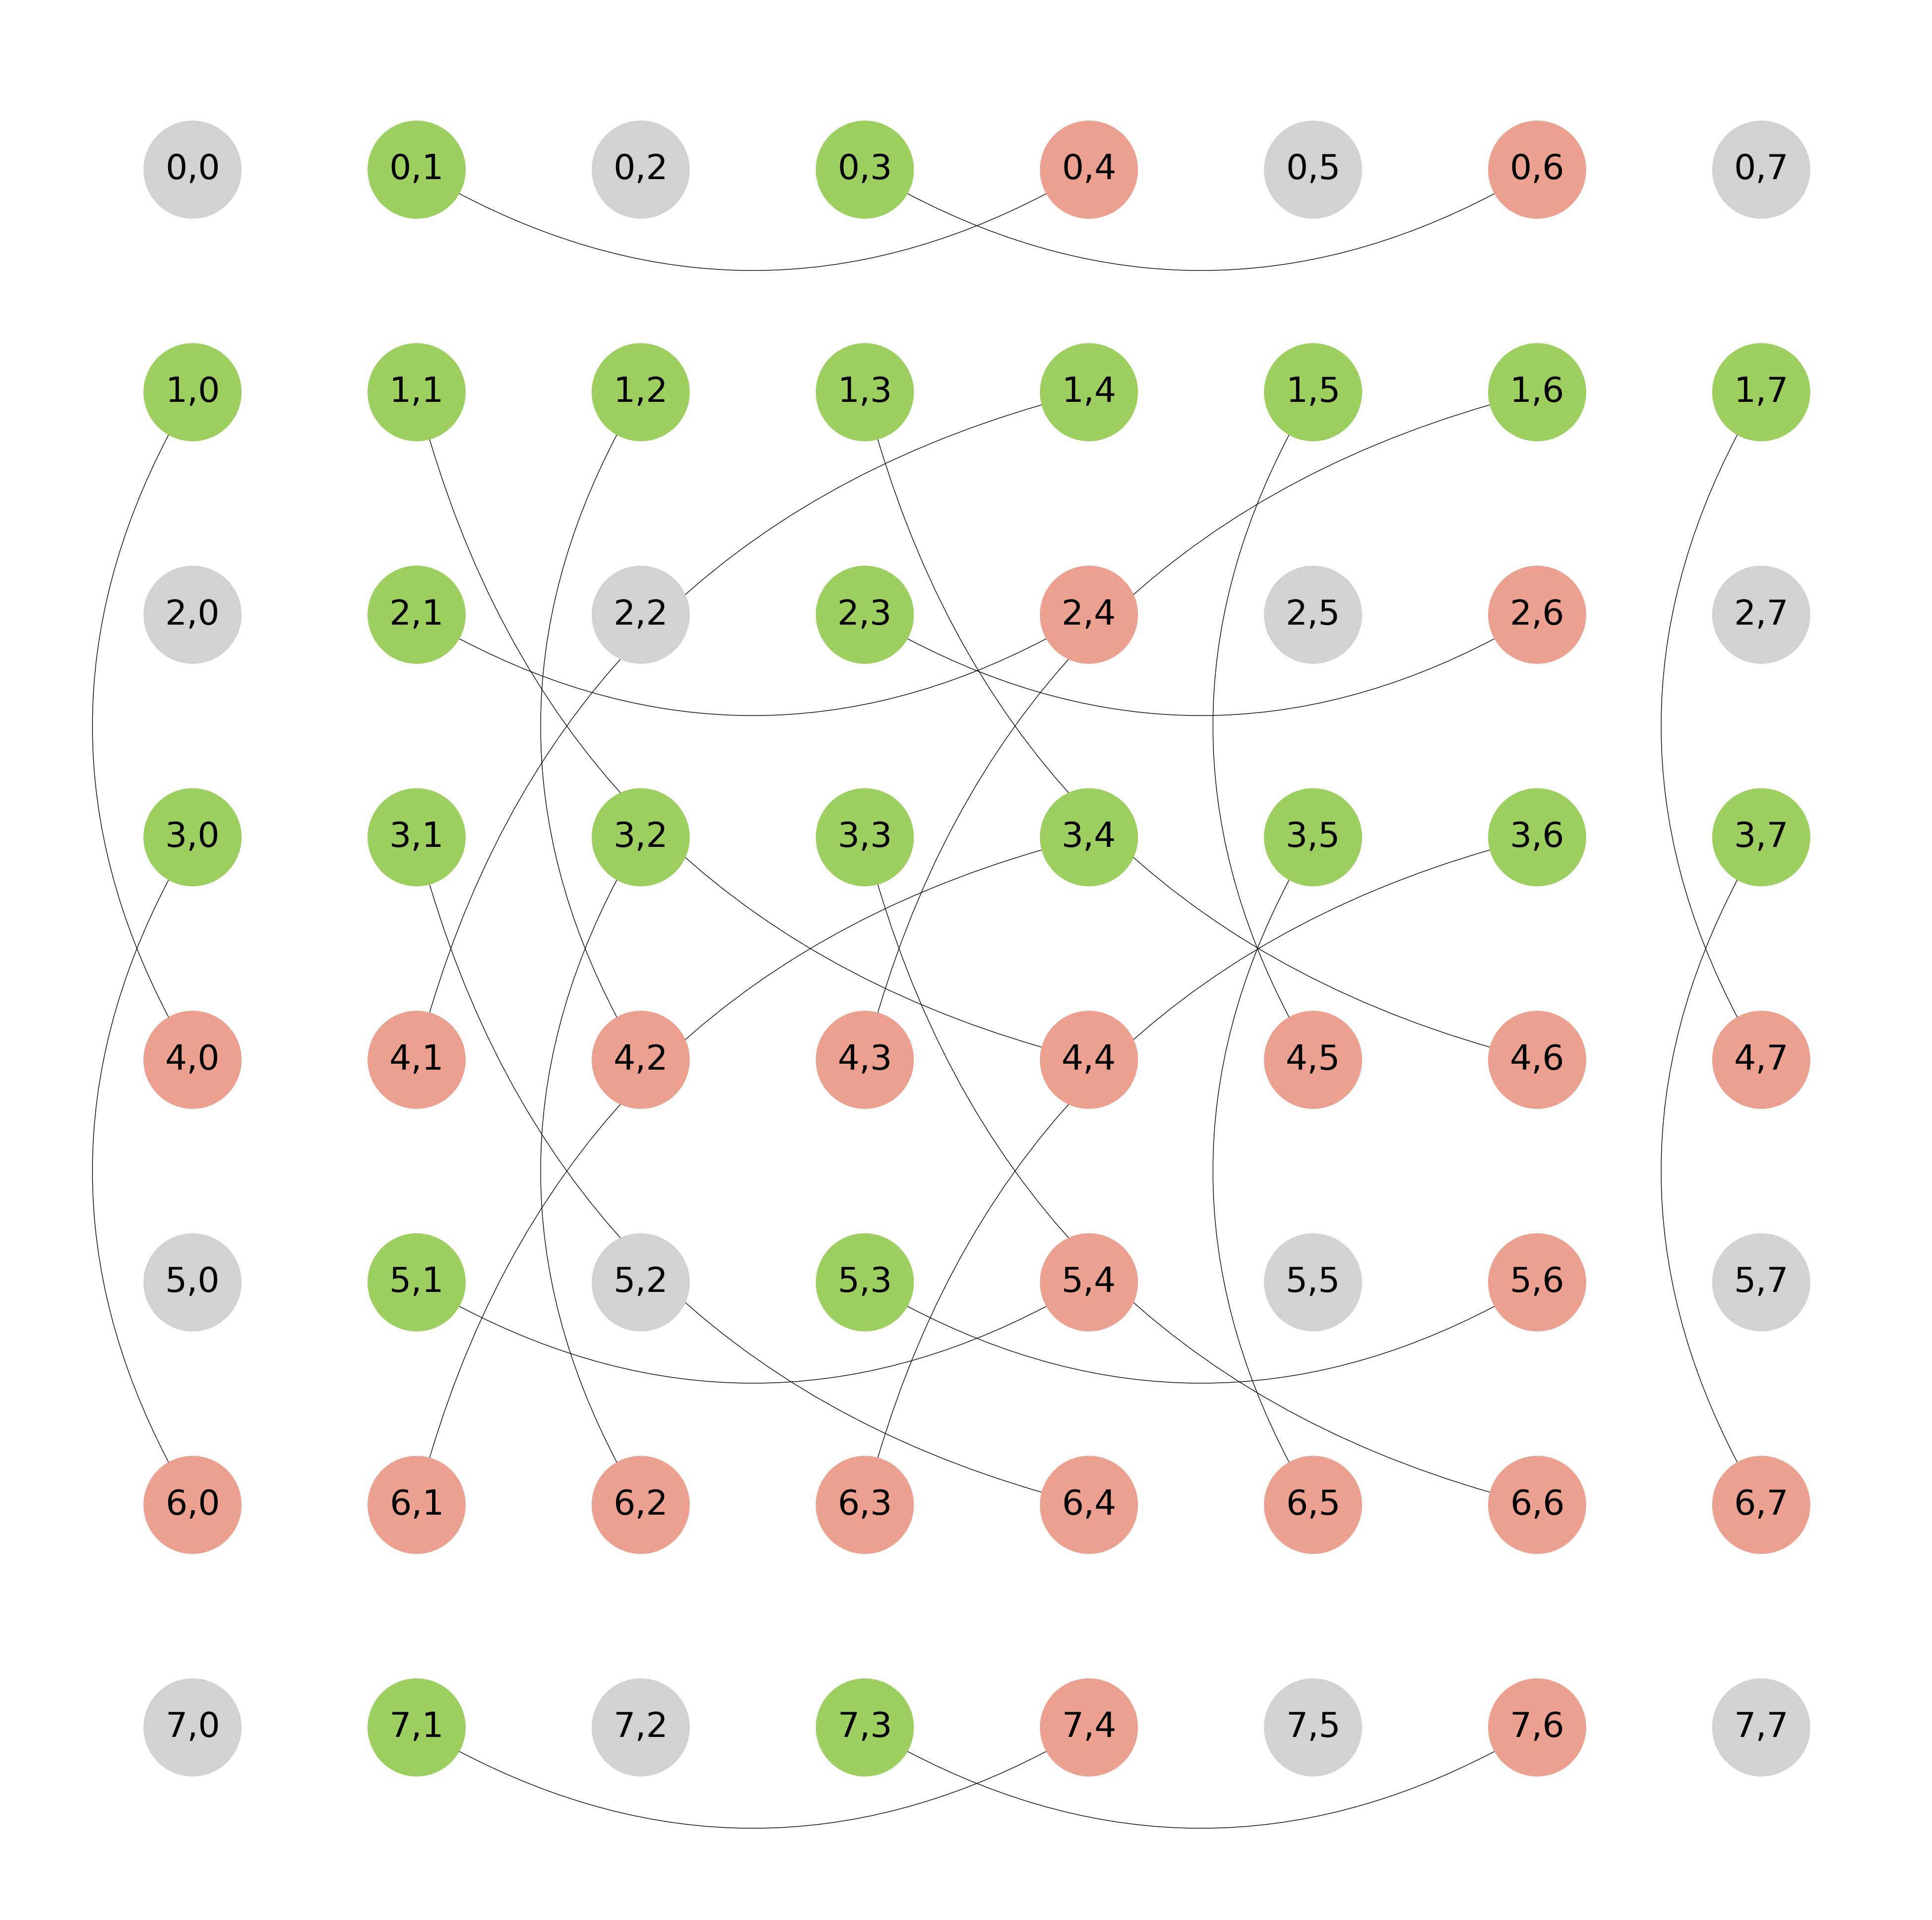

In [21]:
def matrix_transposition(N):
  G = nx.Graph()
  for g in range(1):
    for i in range(N):
      for j in range(N):
        G.add_node(f'{i},{j}')

  get_corr = lambda x: (int(x.split(',')[0]), int(x.split(',')[1]))
  pos = {k: (get_corr(k)[1], N - 1 - get_corr(k)[0]) for k in G.nodes()}

  import math

  def revbits(v, n):
    lg_n = int(math.log2(n))
    for i in range(n):
      revi = 0
      for l in range(lg_n):
          revi |= ((i >> l) & 1) << (lg_n - l - 1)
      v[i] = revi

  rev_n = [0]*N
  rev_m = [0]*N
  revbits(rev_n, N)
  revbits(rev_m, N)

  edges = list()
  node_colors = {}
  for i in range(N):
    rev_i = rev_n[i]
    for j in range(N):
      if (i < rev_i) or ((i == rev_i) and (j < rev_m[j])):
        node_colors[f'{i},{j}'] = 'green'
        node_colors[f'{rev_i},{rev_m[j]}'] = 'yellow'

        node_colors[f'{i},{j}'] = '#9dcf60'
        node_colors[f'{rev_i},{rev_m[j]}'] = '#eca08f'

        edges.append(((f'{i},{j}', 0), (f'{rev_i},{rev_m[j]}', 0), 'blue'))

  for (a, b, c) in edges:
    G.add_edge(a[0], b[0], color=c)

  plt.figure(figsize=(50, 50))
  plt.axis('off')
  nx.draw_networkx(
    G,
    pos=pos,
    with_labels=True,
    font_size=50,
    # node_shape='s',
    node_color=[node_colors.get(node, '#d2d2d2') for node in G.nodes()],
    connectionstyle='arc3,rad=0.3',
    arrows=True,
    node_size=10000 * 2
  )

# matrix_transposition(4)
matrix_transposition(8)
# matrix_transposition(16)
# matrix_transposition(64)